## Linear regessions

<img src="../data/regression-gif.gif" alt="alt text" width="300" height="200">

A regression is a way to describe how two (or more) things are related to each other. This notebook performs a simple linear regression. The notebook was adapted from [investigate.ai](https://investigate.ai/regression/) and [Dr. Tehreem Qasim](https://www.kaggle.com/code/tehreemkhan111/simple-linear-regression).



In [37]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [38]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

### Performing a linear regression
First we will load our data

In [39]:
df = pd.read_csv('../data/salary_data.csv')
print(len(df))

df.head()

30


,YearsExperience,Salary,promoted
0,1.1,39343.0,0
1,1.3,46205.0,0
2,1.5,37731.0,0
3,2.0,43525.0,1
4,2.2,39891.0,0


Using the library statsmodels we can run linear regressions with dataframes. 

In [40]:
X = df['YearsExperience']
y = df["Salary"]

Below we do two things: 
We define `YearsExperience` as the dependent variable. 

Ordinary Least Squares function from the statsmodels library. OLS is a common technique used in analyzing linear regression. In brief, it compares the difference between individual points in your data set and the predicted best fit line to measure the amount of error produced. (Source: [Medium](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a)).

In [41]:
# Use OLS to analyze the regression
model = sm.OLS(y, X)
results = model.fit()

#### Examining our results

We stored out regression in a variable called `results`. Now we can look at the results but using the `.summary()` function to print out the entire regression result.



In [42]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 Salary   R-squared (uncentered):                   0.973
Model:                            OLS   Adj. R-squared (uncentered):              0.972
Method:                 Least Squares   F-statistic:                              1048.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):                    2.56e-24
Time:                        16:24:32   Log-Likelihood:                         -327.28
No. Observations:                  30   AIC:                                      656.6
Df Residuals:                      29   BIC:                                      658.0
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
YearsExperience  1.325e+04    409.401     32.376      0.000    1.24e+04    1.41e+04
==============================================================================
Omnibus:                        0.610   Durbin-Watson:                   0.323
Prob(Omnibus):                  0.737   Jarque-Bera (JB):                0.671
Skew:                          -0.121   Prob(JB):                        0.715
Kurtosis:                       2.308   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### How to interpret your results


Our dependent variable is **Salary**, meaning we were interested in how much our Salary is dependent on the number of years. The information below is a summary of this [Medium post](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a), this [Mediun post](https://medium.com/analytics-vidhya/how-to-interpret-result-from-linear-regression-3f7ae7679ef9) and this [Medium post](https://blog.dailydoseofds.com/p/statsmodel-regression-summary-will).

<img src="../data/regression_illustration.png" alt="alt text" width="800">

Here are some of the things we want to pay special attention to:

- `Model Summary`
    - `R-squared`: R-squared is possibly the most important measurement produced by this summary. R-squared is the measurement of how much of the independent variable is explained by changes in our dependent variables. In percentage terms, 0.957 would mean our model explains 95.7% of the change in our ‘Salary’ variable.
    - `Adj. R-squared`: This is the modified version of R-squared which is adjusted for the number of variables in the regression. It increases only when an additional variable adds to the explanatory power to the regression.
- `Coefficients`: These show the estimated effect of each independent variable on the dependent variable.
    - `Constants`: The constant 2.579e+04 (or 25,790) represents the expected Salary when YearsExperience is zero. However, interpret this cautiously as it may not be meaningful in real-world context.
    -  `YearsExperience`: For each additional year of experience, the model predicts an increase of about 9,450 in Salary, holding other factors constant. 
    - `P-values`: These indicate the statistical significance of each coefficient. These indicate the statistical significance of each coefficient. Generally, a p-value < 0.05 is considered statistically significant.

### Plotting our linear regression
In the next few lines we will plot our linear regression. It can help us understand what the linear regression above is doing.

Text(0, 0.5, 'Salary')

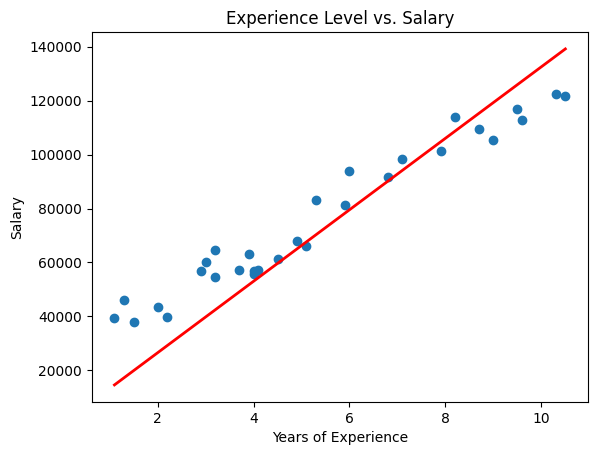

In [43]:
#Plot points
plt.scatter(df["YearsExperience"], df["Salary"])

#Draw the regression line
plt.plot(
    df["YearsExperience"],
    results.predict(),
    color='red',
    linewidth=2,
    label = 'Regression Line'
)

#Add label
plt.title("Experience Level vs. Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")

## Logistic regression!

How does years of experience affect whether or not someone is promoted?

Independent variable: years of experience
Dependent variable: promotion status

In [44]:
df.head()

,YearsExperience,Salary,promoted
0,1.1,39343.0,0
1,1.3,46205.0,0
2,1.5,37731.0,0
3,2.0,43525.0,1
4,2.2,39891.0,0


In [45]:
import statsmodels.formula.api as smf

In [46]:
model = smf.logit(formula='promoted ~ YearsExperience', data=df)
results = model.fit()

Optimization terminated successfully.
         Current function value: 0.635838
         Iterations 5
